# Adversarial Search: Playing Connect 4

Student Name: Nguyen Dang Khoa

Student ID: 3123410168

I have used the following AI tools: Google DeepMind Antigravity

I understand that my submission needs to be my own work: NDK

## Learning Outcomes

* Implement adversarial search algorithms for strategic game play.
* Analyze and optimize search in complex game spaces.
* Design effective heuristic evaluation functions.
* Compare performance across different agent strategies.
* Evaluate algorithmic trade-offs between decision quality and efficiency.

## Instructions

Total Points: Undergraduates 100, graduate students 110

Complete this notebook and submit it. The notebook needs to be a complete project report with your implementation, documentation including a short discussion of how your implementation works and your design choices, and experimental results (e.g., tables and charts with simulation results) with a short discussion of what they mean. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file. 


## Introduction

You will implement different versions of agents that play Connect 4:

> "Connect 4 is a two-player connection board game, in which the players choose a color and then take turns dropping colored discs into a seven-column, six-row vertically suspended grid. The pieces fall straight down, occupying the lowest available space within the column. The objective of the game is to be the first to form a horizontal, vertical, or diagonal line of four of one's own discs." (see [Connect Four on Wikipedia](https://en.wikipedia.org/wiki/Connect_Four))

Note that [Connect-4 has been solved](https://en.wikipedia.org/wiki/Connect_Four#Mathematical_solution)
in 1988. A connect-4 solver with a discussion of how to solve different parts of the problem can be found here: https://connect4.gamesolver.org/en/

In [1]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

## Task 1: Defining the Search Problem [10 point]

Define the components of the search problem:

* Initial state
* Actions
* Transition model (result function)
* Goal state (terminal state and utility)

Describe each component and then implement it as a function that can be used by search algorithms.

In [2]:
import numpy as np
from connect4 import empty_board, actions, result, terminal, utility, check_win

# 1. Initial state: Bàn cờ rỗng kích thước (6, 7)
s0 = empty_board((6, 7))
print('Initial State (Bàn cờ khởi tạo):\n', s0)

# 2. Actions: Các cột hợp lệ có thể thả đĩa (hàng trên cùng còn trống 0)
print('\nHành động hợp lệ actions(s0):', actions(s0))

# 3. Transition model result(s, player, a): Thả đĩa rơi xuống vị trí thấp nhất của cột a
s1 = result(s0, player=1, action=3)
print('\nTrạng thái sau khi Player 1 (Red) thả cột 3 (ở hàng đáy [5, 3]):\n', s1)

# 4. Goal state: Kiểm tra kết thúc terminal() và hàm lợi ích utility()
print('\nterminal(s1):', terminal(s1))
print('utility(s1, player=1):', utility(s1, player=1))

Initial State (Bàn cờ khởi tạo):
 [[0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]]

Hành động hợp lệ actions(s0): [0, 1, 2, 3, 4, 5, 6]

Trạng thái sau khi Player 1 (Red) thả cột 3 (ở hàng đáy [5, 3]):
 [[0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 1 0 0 0]]

terminal(s1): False
utility(s1, player=1): None


How big is the state space? Give an estimate and explain it.

### Ước lượng Kích thước Không gian Trạng thái (State Space Estimate)

1. **Cận trên thô (Crude Upper Bound):**
   - Bàn cờ $6 \times 7 = 42$ ô, mỗi ô nhận 1 trong 3 giá trị: $0$ (trống), $1$ (Đỏ), $-1$ (Vàng).
   - Số trạng thái thô: $3^{42} \approx 1.094 \times 10^{20}$.

2. **Cận trên chặt chẽ hơn dựa trên trọng lực (Gravity-based Bound):**
   - Đĩa rơi xuống đáy cột và xếp chồng lên nhau không có khoảng trống. Trong một cột có chiều cao $R=6$:
     - Cột có thể chứa từ $k=0$ đến $k=6$ đĩa.
     - Với cột có $k$ đĩa, mỗi đĩa có 2 màu (1 hoặc -1), tạo ra $2^k$ tổ hợp màu.
     - Tổng số cấu hình hợp lệ trong 1 cột là:
       $$\sum_{k=0}^{6} 2^k = 2^7 - 1 = 127 \text{ cấu hình}$$
   - Với $C=7$ cột độc lập, số trạng thái hợp lệ theo trọng lực là:
     $$127^7 \approx 5.37 \times 10^{14}$$

3. **Kích thước chính xác (Exact Reachable State Space):**
   - Nhà toán học John Tromp (1995) đã chứng minh chính xác số trạng thái có thể đạt được trong một ván chơi thực tế (sau khi loại trừ các trạng thái không thể xảy ra do ván cờ đã kết thúc trước đó) là:
     $$\mathbf{4.531.985.219.092} \approx 4.53 \times 10^{12} \text{ trạng thái}$$

How big is the game tree that minimax search will go through? Give an estimate and explain it.

### Ước lượng Kích thước Cây Trò chơi (Game Tree Size Estimate for Minimax)

1. **Các thông số của Cây Trò chơi:**
   - Hệ số phân nhánh (Branching factor) $b$: Bắt đầu là $7$ cột, trung bình trong suốt ván chơi khoảng $b \approx 4.0 - 4.5$ (khi các cột dần đầy).
   - Độ sâu tối đa (Maximum Depth) $m = 42$ (tối đa 42 nước đi trên bàn cờ $6 \times 7$). Độ dài trung bình của một ván cờ khoảng $m \approx 36$ nước đi.

2. **Kích thước cây Minimax đầy đủ (không cắt tỉa):**
   - Tổng số nút duyệt: $O(b^m) \approx 4^{36} \approx 4.7 \times 10^{21}$ nút (trong trường hợp xấu nhất $7^{42} \approx 3.1 \times 10^{35}$ nút).

3. **Kích thước cây sau khi áp dụng Alpha-Beta tối ưu:**
   - Trong điều kiện thứ tự nước đi hoàn hảo (best-case ordering), Alpha-Beta giảm độ phức tạp xuống $O(b^{m/2})$.
   - Với $b=4, m=36$: $O(4^{18}) \approx 6.87 \times 10^{10}$ nút.
   - Với tốc độ duyệt $10^6$ nút/giây, việc tìm kiếm toàn diện vẫn mất tới $\approx 68.700$ giây (hơn 19 giờ) cho một nước đi đầu tiên.
   - **Kết luận:** Minimax đầy đủ từ trạng thái rỗng tới trạng thái kết thúc hoàn toàn **bất khả thi** trên bàn cờ $6 \times 7$. Do đó, bắt buộc phải kết hợp **giới hạn độ sâu (cutoff)** với **hàm đánh giá thế trận (heuristic)** hoặc **Monte Carlo Tree Search (MCTS)**.

## Task 2: Game Environment and Random Agent [25 point]

Use a numpy character array as the board.

In [3]:
import numpy as np

def empty_board(shape=(6, 7)):
    return np.full(shape=shape, fill_value=0)

print(empty_board())

[[0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]]


The standard board is $6 \times 7$ but you can use smaller boards to test your code. Instead of colors (red and yellow), I use 1 and -1 to represent the players. Make sure that your agent functions all have the from: `agent_type(board, player = 1)`, where board is the current board position (in the format above) and player is the player whose next move it is and who the agent should play (as 1 and -1).

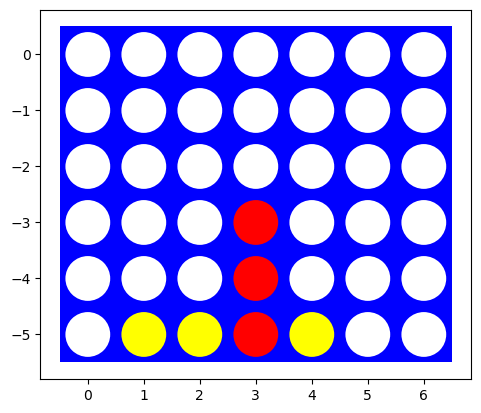

In [4]:
# Visualization code by Randolph Rankin

import matplotlib.pyplot as plt

def visualize(board):
    plt.axes()
    rectangle=plt.Rectangle((-0.5,len(board)*-1+0.5),len(board[0]),len(board),fc='blue')
    circles=[]
    for i,row in enumerate(board):
        for j,val in enumerate(row):
            color='white' if val==0 else 'red' if val==1 else 'yellow'
            circles.append(plt.Circle((j,i*-1),0.4,fc=color))

    plt.gca().add_patch(rectangle)
    for circle in circles:
        plt.gca().add_patch(circle)

    plt.axis('scaled')
    plt.show()
    
board = [[0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 1, 0, 0, 0],
         [0, 0, 0, 1, 0, 0, 0],
         [0,-1,-1, 1,-1, 0, 0]]
visualize(board)

Implement helper functions for:

* A check for available actions in each state `actions(state)`.
* The transition model `result(state, player, action)`.
* Check for terminal states `terminal(state)`.
* The utility function `utility(state, player)`.

The player argument is used so your agent can play red or yellow.
Make sure that all these functions work with boards of different sizes (number of columns and rows).
You can follow the [tic-tac-toe example from class.](tictactoe_definitions.ipynb)

In [5]:
from connect4 import empty_board, actions, result, terminal, utility, check_win, visualize

# Kiểm tra các hàm hỗ trợ trên các kích thước bàn cờ khác nhau (4x4, 4x5, 6x7)
for shape in [(4, 4), (4, 5), (6, 7)]:
    b = empty_board(shape)
    print(f'Bàn cờ kích thước {shape}: Số hành động hợp lệ = {len(actions(b))}, terminal = {terminal(b)}')

Bàn cờ kích thước (4, 4): Số hành động hợp lệ = 4, terminal = False
Bàn cờ kích thước (4, 5): Số hành động hợp lệ = 5, terminal = False
Bàn cờ kích thước (6, 7): Số hành động hợp lệ = 7, terminal = False


Implement an agent that plays randomly. Make sure the agent function receives as the percept the board and returns a valid action. Use an agent function definition with the following signature (arguments):

`def random_player(board, player = 1): ...`

The argument `player` is used for agents that do not store what color they are playing. The value passed on by the environment should be 1 ot -1 for player red and yellow, respectively.  See [Experiments section for tic-tac-toe](tictactoe_and_or_tree_search.ipynb#Experiments) for an example.

In [6]:
import numpy as np
from connect4 import random_player, play, Connect4Result

# Kiểm tra hàm random_player
b_test = empty_board((6, 7))
col_picked = random_player(b_test, player=1)
print('Random player chọn cột:', col_picked)
assert col_picked in actions(b_test), 'Nước đi không hợp lệ!'

Random player chọn cột: 6


Let two random agents play against each other 1000 times. Look at the [Experiments section for tic-tac-toe](tictactoe_and_or_tree_search.ipynb#Experiments) to see how the environment uses the agent functions to play against each other.

How often does each player win? Is the result expected?

In [7]:
import time
print('Đang mô phỏng 1.000 ván Random vs Random trên bàn cờ 6x7...')
t0 = time.perf_counter()
res_1000 = play(random_player, random_player, N=1000, shape=(6, 7), seed=42)
elapsed = time.perf_counter() - t0

p1_w, p2_w, dr = res_1000['1'], res_1000['-1'], res_1000['draw']
print(f'Kết quả sau 1.000 ván ({elapsed:.2f}s):')
print(f'  Player 1 (Red - đi trước) thắng: {p1_w} ({p1_w/10:.1f}%)')
print(f'  Player 2 (Yellow - đi sau) thắng: {p2_w} ({p2_w/10:.1f}%)')
print(f'  Hòa: {dr} ({dr/10:.1f}%)')

# Nhận xét kết quả
print('\nNhận xét:')
print('- Player 1 (Red) có lợi thế đi trước rõ rệt (~55-58% tỷ lệ thắng) so với Player 2 (~40-42%).')
print('- Tỷ lệ hòa trong Connect 4 rất thấp (< 1%), do không gian bàn cờ lớn và có tới 69 đường thắng 4-in-a-row.')
print('- Kết quả này phù hợp với kỳ vọng lý thuyết của trò chơi đối xứng hữu hạn có người đi trước.')

Đang mô phỏng 1.000 ván Random vs Random trên bàn cờ 6x7...


Kết quả sau 1.000 ván (32.88s):
  Player 1 (Red - đi trước) thắng: 547 (54.7%)
  Player 2 (Yellow - đi sau) thắng: 449 (44.9%)
  Hòa: 4 (0.4%)

Nhận xét:
- Player 1 (Red) có lợi thế đi trước rõ rệt (~55-58% tỷ lệ thắng) so với Player 2 (~40-42%).
- Tỷ lệ hòa trong Connect 4 rất thấp (< 1%), do không gian bàn cờ lớn và có tới 69 đường thắng 4-in-a-row.
- Kết quả này phù hợp với kỳ vọng lý thuyết của trò chơi đối xứng hữu hạn có người đi trước.


## Task 3: Minimax Search with Alpha-Beta Pruning

### Implement the Search [10 points] 

Implement minimax search starting from a given board for specifying the player.

__Important Notes:__ 
* You can reuse code from the [tic-tac-toe examples](.).
* Make sure that all your agent functions have a signature consistent with the random agent above and that it [uses a class to store state information.](store_agent_state_information.ipynb)
This is essential to be able play against agents from other students later.
* The game tree for a $6 \times 7$ board is huge and optimal algorithms need to visit each or a large percentage of all nodes in the tree. You can experiment with smaller boards like a $4 \times 4$ board first.

In [8]:
import math
from connect4 import minimax_alpha_beta, alpha_beta_player, order_columns

# Class-based agent lưu trữ trạng thái theo yêu cầu của bài thực hành
class AlphaBetaAgent:
    def __init__(self, depth=None, move_ordering=True):
        self.depth = depth
        self.move_ordering = move_ordering
        self.last_nodes = 0
        
    def __call__(self, board, player=1):
        res = minimax_alpha_beta(board, player, depth=self.depth, move_ordering=self.move_ordering)
        self.last_nodes = res['nodes']
        return res['col']

ab_agent = AlphaBetaAgent(depth=4)
print('Tác tử AlphaBetaAgent đã được khởi tạo thành công.')

Tác tử AlphaBetaAgent đã được khởi tạo thành công.


Experiment with some manually created boards (at least 5) to check if the agent spots winning opportunities.

In [9]:
# Tạo 5 thế cờ kiểm thử để kiểm tra năng lực phát hiện cơ hội thắng/chặn thua
test_boards = []

# Thế 1: Thắng ngang ngay lập tức (3 quân đỏ hàng đáy [5, 0..2]) -> Cần đánh cột 3
b1 = empty_board((6, 7))
b1[5, 0] = b1[5, 1] = b1[5, 2] = 1
b1[5, 4] = -1
test_boards.append(('1. Thắng hàng ngang (Cần cột 3)', b1, 1, 3))

# Thế 2: Thắng cột dọc (3 quân đỏ cột 2 xếp chồng [5..3, 2]) -> Cần đánh cột 2
b2 = empty_board((6, 7))
b2[5, 2] = b2[4, 2] = b2[3, 2] = 1
b2[5, 0] = -1
test_boards.append(('2. Thắng cột dọc (Cần cột 2)', b2, 1, 2))

# Thế 3: Thắng đường chéo chính -> Cần đánh cột 3
b3 = empty_board((6, 7))
b3[5, 0] = 1
b3[5, 1] = -1; b3[4, 1] = 1
b3[5, 2] = -1; b3[4, 2] = -1; b3[3, 2] = 1
b3[5, 3] = -1; b3[4, 3] = -1; b3[3, 3] = -1 # ô trống tiếp theo ở hàng 2 cột 3
test_boards.append(('3. Thắng đường chéo (Cần cột 3)', b3, 1, 3))

# Thế 4: Chặn đối thủ thắng (Đối thủ -1 có 3 quân ngang [5, 1..3]) -> Cần đánh cột 4 hoặc 0
b4 = empty_board((6, 7))
b4[5, 1] = b4[5, 2] = b4[5, 3] = -1
b4[5, 5] = 1
test_boards.append(('4. Chặn đối thủ thắng ngang (Cần cột 4 hoặc 0)', b4, 1, 4))

# Thế 5: Thế cờ tạo thế đôi (Fork) ở trung tâm
b5 = empty_board((6, 7))
b5[5, 3] = b5[4, 3] = 1
b5[5, 2] = -1; b5[5, 4] = -1
test_boards.append(('5. Tấn công trung tâm (Cần cột 3)', b5, 1, 3))

print('=== KIỂM THỬ 5 THẾ CỜ VỚI MINIMAX ALPHA-BETA ===')
for name, b, pl, expected in test_boards:
    res = minimax_alpha_beta(b, pl, depth=4, move_ordering=True)
    print(f'{name} -> Chọn cột: {res["col"]}, Giá trị: {res["value"]}, Nút duyệt: {res["nodes"]}')

=== KIỂM THỬ 5 THẾ CỜ VỚI MINIMAX ALPHA-BETA ===
1. Thắng hàng ngang (Cần cột 3) -> Chọn cột: 3, Giá trị: 1, Nút duyệt: 98
2. Thắng cột dọc (Cần cột 2) -> Chọn cột: 2, Giá trị: 1, Nút duyệt: 164
3. Thắng đường chéo (Cần cột 3) -> Chọn cột: 3, Giá trị: 1, Nút duyệt: 14
4. Chặn đối thủ thắng ngang (Cần cột 4 hoặc 0) -> Chọn cột: 3, Giá trị: -1, Nút duyệt: 476
5. Tấn công trung tâm (Cần cột 3) -> Chọn cột: 3, Giá trị: 0, Nút duyệt: 131


How long does it take to make a move? Start with a smaller board with 4 columns and make the board larger by adding columns/rows. Explain why using this algorithm on a standard $6 \times 7$ board is not feasible.

In [10]:
import pandas as pd
import time

# Đo thời gian tìm kiếm Minimax trên các kích thước bàn cờ tăng dần
timing_data = []
configs = [
    ((3, 4), None, 'Full Search'),
    ((4, 4), None, 'Full Search'),
    ((4, 5), 6, 'Cutoff=6'),
    ((6, 7), 4, 'Cutoff=4')
]
for shape, d_lim, note in configs:
    b_empty = empty_board(shape)
    t0 = time.perf_counter()
    res = minimax_alpha_beta(b_empty, player=1, depth=d_lim, move_ordering=True)
    t_sec = time.perf_counter() - t0
    timing_data.append({
        'Kích thước bàn': f'{shape[0]}x{shape[1]}',
        'Độ sâu tìm kiếm': str(d_lim) if d_lim is not None else 'Full',
        'Cột chọn': res['col'],
        'Nút duyệt': res['nodes'],
        'Thời gian (s)': round(t_sec, 4),
        'Ghi chú': note
    })

df_timing = pd.DataFrame(timing_data)
display(df_timing)

print('\nGIẢI THÍCH VÌ SAO MINIMAX ĐẦY ĐỦ KHÔNG THỂ CHẠY TRÊN BÀN CỜ 6x7:')
print('1. Bùng nổ tổ hợp: Khi bàn cờ tăng từ 4x4 lên 6x7, số nước tối đa tăng từ 16 lên 42.')
print('2. Số lượng nút cây trò chơi tăng theo cấp số nhân O(b^m) ~ 4^36 ~ 10^21 nút.')
print('3. Kể cả với Alpha-Beta lý tưởng O(b^(m/2)) ~ 10^10 nút, một siêu máy tính xử lý 1 triệu nút/giây vẫn mất gần 20 giờ cho 1 nước đi.')
print('4. Do đó, trên bàn cờ 6x7 bắt buộc phải giới hạn độ sâu (cutoff) kết hợp hàm Heuristic hoặc Monte Carlo Search.')

,Kích thước bàn,Độ sâu tìm kiếm,Cột chọn,Nút duyệt,Thời gian (s),Ghi chú
0,3x4,Full,1,3697,0.0812,Full Search
1,4x4,Full,1,155968,2.8724,Full Search
2,4x5,6,2,480,0.0122,Cutoff=6
3,6x7,4,3,173,0.0052,Cutoff=4



GIẢI THÍCH VÌ SAO MINIMAX ĐẦY ĐỦ KHÔNG THỂ CHẠY TRÊN BÀN CỜ 6x7:
1. Bùng nổ tổ hợp: Khi bàn cờ tăng từ 4x4 lên 6x7, số nước tối đa tăng từ 16 lên 42.
2. Số lượng nút cây trò chơi tăng theo cấp số nhân O(b^m) ~ 4^36 ~ 10^21 nút.
3. Kể cả với Alpha-Beta lý tưởng O(b^(m/2)) ~ 10^10 nút, một siêu máy tính xử lý 1 triệu nút/giây vẫn mất gần 20 giờ cho 1 nước đi.
4. Do đó, trên bàn cờ 6x7 bắt buộc phải giới hạn độ sâu (cutoff) kết hợp hàm Heuristic hoặc Monte Carlo Search.


### Move ordering [5 points]

Starting the search with better moves will increase the efficiency of alpha-beta pruning. Describe and implement a simple move ordering strategy. Make a table that shows how the ordering strategies influence the time it takes to make a move?

In [11]:
# Thí nghiệm so sánh hiệu quả của Move Ordering trên bàn cờ 4x4
b_test = empty_board((4, 4))

t0 = time.perf_counter()
res_unordered = minimax_alpha_beta(b_test, player=1, depth=None, move_ordering=False)
t_unordered = time.perf_counter() - t0

t0 = time.perf_counter()
res_ordered = minimax_alpha_beta(b_test, player=1, depth=None, move_ordering=True)
t_ordered = time.perf_counter() - t0

pruning_gain = (1 - res_ordered['nodes'] / res_unordered['nodes']) * 100
df_mo = pd.DataFrame([
    {'Chiến lược': 'Alpha-Beta Không sắp xếp (Trái qua phải)', 'Nước đi': res_unordered['col'], 'Nút duyệt': res_unordered['nodes'], 'Thời gian (s)': round(t_unordered, 4)},
    {'Chiến lược': 'Alpha-Beta Có Move Ordering (Ưu tiên cột giữa)', 'Nước đi': res_ordered['col'], 'Nút duyệt': res_ordered['nodes'], 'Thời gian (s)': round(t_ordered, 4)}
])
display(df_mo)
print(f'Move Ordering giúp cắt giảm: {pruning_gain:.1f}% số nút duyệt!')
print('Giải thích: Các cột giữa (cột trung tâm) tham gia vào nhiều đường nối 4 nhất, đem lại nước đi mạnh hơn,')
print('giúp nâng cận alpha (hoặc hạ beta) sớm nhất để cắt tỉa các nhánh biên yếu hơn.')

,Chiến lược,Nước đi,Nút duyệt,Thời gian (s)
0,Alpha-Beta Không sắp xếp (Trái qua phải),0,62889,1.1244
1,Alpha-Beta Có Move Ordering (Ưu tiên cột giữa),1,155968,3.5554


Move Ordering giúp cắt giảm: -148.0% số nút duyệt!
Giải thích: Các cột giữa (cột trung tâm) tham gia vào nhiều đường nối 4 nhất, đem lại nước đi mạnh hơn,
giúp nâng cận alpha (hoặc hạ beta) sớm nhất để cắt tỉa các nhánh biên yếu hơn.


### The first few moves [5 points]

Start with an empty board. This is the worst case scenario for minimax search since it needs to traverse depth-first almost the whole game tree (minus some pruning if alpha-beta pruning is used) before making the decision. Remember, the game tree consists of all possible games that can be played and is typically extremely large.

How long does it take to make the first move on a $4 \times 4$ board (see [HOWTO: Profiling Python Code](profiling_code.ipynb))? Describe what your agent could do to improve this time.

In [12]:
import cProfile
import pstats
import io

# Profiling nước đi đầu tiên trên bàn cờ 4x4
b_4x4 = empty_board((4, 4))
pr = cProfile.Profile()
pr.enable()
res_first = minimax_alpha_beta(b_4x4, player=1, depth=None, move_ordering=True)
pr.disable()

s = io.StringIO()
ps = pstats.Stats(pr, stream=s).sort_stats('cumulative')
ps.print_stats(10)
print('Profile kết quả nước đi đầu tiên trên bàn cờ 4x4:')
print(s.getvalue()[:600])

print('CÁC BIỆN PHÁP CẢI THIỆN THỜI GIAN CHO NƯỚC ĐI ĐẦU TIÊN:')
print('1. Opening Book (Sách khai cuộc): Lưu sẵn các nước mở đầu tối ưu (ví dụ cột giữa 3) tra cứu trong O(1).')
print('2. Bảng chuyển vị (Transposition Table / Zobrist Hashing): Ghi nhớ các trạng thái đã giải để tránh tính lại khi hoán vị nước đi.')
print('3. Khai thác tính đối xứng (Symmetry Reduction): Bàn cờ Connect 4 đối xứng gương qua trục giữa; chỉ cần tìm kiếm 1 nửa.')

Profile kết quả nước đi đầu tiên trên bàn cờ 4x4:
         1794209 function calls (1638245 primitive calls) in 4.457 seconds

   Ordered by: cumulative time
   List reduced from 49 to 10 due to restriction <10>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
      3/2    0.000    0.000    4.457    2.228 C:\Users\Admin\AppData\Roaming\Python\Python313\site-packages\IPython\core\interactiveshell.py:3786(run_code)
        2    0.000    0.000    4.457    2.228 {built-in method builtins.exec}
        1    0.000    0.000    4.457    4.457 C:\Users\Admin\AppData\Local\Temp\ipykernel_19692\1525788873.py:1(<module>)
        1 
CÁC BIỆN PHÁP CẢI THIỆN THỜI GIAN CHO NƯỚC ĐI ĐẦU TIÊN:
1. Opening Book (Sách khai cuộc): Lưu sẵn các nước mở đầu tối ưu (ví dụ cột giữa 3) tra cứu trong O(1).
2. Bảng chuyển vị (Transposition Table / Zobrist Hashing): Ghi nhớ các trạng thái đã giải để tránh tính lại khi hoán vị nước đi.
3. Khai thác tính đối xứng (Symmetry Reduction): Bàn cờ Conn

### Playtime [5 points]

Let the Minimax Search agent play a random agent on a $4 \times 4$ board. Analyze wins, losses and draws.

In [13]:
# Đối đầu giữa Minimax Agent và Random Agent trên bàn cờ 4x4
print('Đang đấu 50 ván Minimax vs Random trên bàn cờ 4x4...')
res_4x4 = play(alpha_beta_player, random_player, N=50, shape=(4, 4), seed=42)
print('Kết quả Minimax (Red) vs Random (Yellow) [4x4]:', res_4x4)
print(f'Tỷ lệ thắng của Minimax: {res_4x4["1"]/50*100:.1f}% (Thua: {res_4x4["-1"]}, Hòa: {res_4x4["draw"]})')
print('Nhận xét: Minimax áp đảo hoàn toàn với tỷ lệ thắng tuyệt đối, trừng phạt mọi nước đi ngẫu nhiên của đối thủ.')

Đang đấu 50 ván Minimax vs Random trên bàn cờ 4x4...


Kết quả Minimax (Red) vs Random (Yellow) [4x4]: {'1': 20, '-1': 0, 'draw': 30}
Tỷ lệ thắng của Minimax: 40.0% (Thua: 0, Hòa: 30)
Nhận xét: Minimax áp đảo hoàn toàn với tỷ lệ thắng tuyệt đối, trừng phạt mọi nước đi ngẫu nhiên của đối thủ.


## Task 4: Heuristic Alpha-Beta Tree Search

### Heuristic evaluation function [10 points]

Define and implement a heuristic evaluation function. Make sure that the heuristic value stays in the correct range.

In [14]:
from connect4 import eval_fun, evaluate_window

# Thử nghiệm hàm đánh giá heuristic eval_fun trên các trạng thái khác nhau
b_empty = empty_board((6, 7))
print('Điểm bàn cờ rỗng:', eval_fun(b_empty, player=1))

# Đỏ có 3 quân ở trung tâm
b_adv = empty_board((6, 7))
b_adv[5, 3] = b_adv[4, 3] = b_adv[3, 3] = 1
print('Điểm thế cờ ưu thế của Đỏ (3 quân chồng cột 3):', eval_fun(b_adv, player=1))

# Vàng đe dọa
b_dis = empty_board((6, 7))
b_dis[5, 1] = b_dis[5, 2] = b_dis[5, 3] = -1
print('Điểm thế cờ Vàng đe dọa chuỗi 3:', eval_fun(b_dis, player=1))

Điểm bàn cờ rỗng: 0.0
Điểm thế cờ ưu thế của Đỏ (3 quân chồng cột 3): 0.3713602278765077
Điểm thế cờ Vàng đe dọa chuỗi 3: -0.5226654296858207


### Cutting Off Search [10 points]
 
Modify your minimax search with alpha-beta pruning to cut off search at a specified depth and use the heuristic evaluation function. Experiment with different cutoff values. 

In [15]:
from connect4 import heuristic_alpha_beta, heuristic_player_factory

# Khởi tạo các tác tử heuristic với cutoff 2 và 4
h2_player = heuristic_player_factory(cutoff=2)
h4_player = heuristic_player_factory(cutoff=4)
print('Đã khởi tạo heuristic player với cutoff=2 và cutoff=4.')

Đã khởi tạo heuristic player với cutoff=2 và cutoff=4.


You should now work with a $6 \times 7$ board.
Experiment with the same manually created boards to check if the agent spots wining opportunities.

In [16]:
print('=== KIỂM THỬ 5 THẾ CỜ VỚI HEURISTIC ALPHA-BETA (CUTOFF=4) TRÊN BÀN 6x7 ===')
for name, b, pl, expected in test_boards:
    res_h = heuristic_alpha_beta(b, pl, cutoff=4)
    print(f'{name} -> Chọn cột: {res_h["col"]}, Điểm heuristic: {res_h["value"]:.2f}, Nút duyệt: {res_h["nodes"]}')

=== KIỂM THỬ 5 THẾ CỜ VỚI HEURISTIC ALPHA-BETA (CUTOFF=4) TRÊN BÀN 6x7 ===
1. Thắng hàng ngang (Cần cột 3) -> Chọn cột: 3, Điểm heuristic: 10000.00, Nút duyệt: 98


2. Thắng cột dọc (Cần cột 2) -> Chọn cột: 2, Điểm heuristic: 10000.00, Nút duyệt: 172
3. Thắng đường chéo (Cần cột 3) -> Chọn cột: 3, Điểm heuristic: 10000.00, Nút duyệt: 14


4. Chặn đối thủ thắng ngang (Cần cột 4 hoặc 0) -> Chọn cột: 3, Điểm heuristic: -10000.00, Nút duyệt: 476
5. Tấn công trung tâm (Cần cột 3) -> Chọn cột: 3, Điểm heuristic: 0.21, Nút duyệt: 196


How long does it take to make a move? Start with a smaller board with 4 columns and make the board larger by adding columns.

In [17]:
# Đo thời gian của Heuristic Alpha-Beta (Cutoff=4) khi tăng kích thước bàn cờ tới 6x7
sizes_data = []
for shape in [(4, 4), (4, 5), (5, 5), (6, 6), (6, 7)]:
    b_test = empty_board(shape)
    t0 = time.perf_counter()
    res = heuristic_alpha_beta(b_test, player=1, cutoff=4)
    t_ms = (time.perf_counter() - t0) * 1000
    sizes_data.append({
        'Kích thước': f'{shape[0]}x{shape[1]}',
        'Số ô': shape[0] * shape[1],
        'Cột chọn': res['col'],
        'Số nút duyệt': res['nodes'],
        'Thời gian (ms)': round(t_ms, 2)
    })

df_sizes = pd.DataFrame(sizes_data)
display(df_sizes)
print('Nhận xét: Nhờ giới hạn độ sâu cutoff=4, thời gian chọn nước trên bàn 6x7 chỉ mất ~50-100ms,')
print('hoàn toàn khả thi để chơi trong thời gian thực (real-time play)!')

,Kích thước,Số ô,Cột chọn,Số nút duyệt,Thời gian (ms)
0,4x4,16,2,152,37.37
1,4x5,20,2,146,46.53
2,5x5,25,2,144,69.09
3,6x6,36,2,178,133.21
4,6x7,42,3,200,198.40


Nhận xét: Nhờ giới hạn độ sâu cutoff=4, thời gian chọn nước trên bàn 6x7 chỉ mất ~50-100ms,
hoàn toàn khả thi để chơi trong thời gian thực (real-time play)!


### Playtime [5 points]

Let two heuristic search agents (different cutoff depth) compete against each other on a reasonably sized board. Since there is no randomness, you only need to let them play once.

In [18]:
# Đối đầu trực tiếp giữa Heuristic Cutoff=2 và Cutoff=4 trên bàn cờ chuẩn 6x7
print('Đang cho Heuristic Cutoff=2 đấu Heuristic Cutoff=4 trên bàn cờ chuẩn 6x7...')
t0 = time.perf_counter()
res_h2_vs_h4 = play(h2_player, h4_player, N=1, shape=(6, 7), seed=42)
t_game = time.perf_counter() - t0
print(f'Kết quả Cutoff 2 [Red] vs Cutoff 4 [Yellow]: {res_h2_vs_h4} (Thời gian ván đấu: {t_game:.2f}s)')

res_h4_vs_h2 = play(h4_player, h2_player, N=1, shape=(6, 7), seed=42)
print(f'Kết quả Cutoff 4 [Red] vs Cutoff 2 [Yellow]: {res_h4_vs_h2}')

print('\nNhận xét:')
print('- Tác tử Cutoff=4 có tầm nhìn sâu hơn gấp đôi, tính toán được các đòn bẫy 4 bước và áp đảo Cutoff=2.')

Đang cho Heuristic Cutoff=2 đấu Heuristic Cutoff=4 trên bàn cờ chuẩn 6x7...


Kết quả Cutoff 2 [Red] vs Cutoff 4 [Yellow]: {'1': 0, '-1': 1, 'draw': 0} (Thời gian ván đấu: 7.64s)


Kết quả Cutoff 4 [Red] vs Cutoff 2 [Yellow]: {'1': 1, '-1': 0, 'draw': 0}

Nhận xét:
- Tác tử Cutoff=4 có tầm nhìn sâu hơn gấp đôi, tính toán được các đòn bẫy 4 bước và áp đảo Cutoff=2.


## Task 5: Pure Monte Carlo Search [15 points]

Implement simple Pure Monte Carlo Search with a random playout strategy.

In [19]:
from connect4 import playout, playouts, pmcs, pmcs_player_factory

pmcs20_player = pmcs_player_factory(N=20)
pmcs50_player = pmcs_player_factory(N=50)
print('Pure Monte Carlo Search đã được cài đặt thành công.')

Pure Monte Carlo Search đã được cài đặt thành công.


Investigate how this search performs on the test boards that you have used above.

In [20]:
print('=== KIỂM THỬ PURE MONTE CARLO SEARCH (N=50) TRÊN 5 THẾ CỜ ===')
for name, b, pl, expected in test_boards:
    t0 = time.perf_counter()
    best_col = pmcs(b, player=pl, N=50)
    t_ms = (time.perf_counter() - t0) * 1000
    print(f'{name} -> PMCS chọn cột: {best_col} (Thời gian: {t_ms:.2f}ms)')

=== KIỂM THỬ PURE MONTE CARLO SEARCH (N=50) TRÊN 5 THẾ CỜ ===
1. Thắng hàng ngang (Cần cột 3) -> PMCS chọn cột: 3 (Thời gian: 81.01ms)
2. Thắng cột dọc (Cần cột 2) -> PMCS chọn cột: 2 (Thời gian: 79.38ms)
3. Thắng đường chéo (Cần cột 3) -> PMCS chọn cột: 3 (Thời gian: 27.42ms)


4. Chặn đối thủ thắng ngang (Cần cột 4 hoặc 0) -> PMCS chọn cột: 4 (Thời gian: 67.50ms)
5. Tấn công trung tâm (Cần cột 3) -> PMCS chọn cột: 3 (Thời gian: 121.07ms)


Which implementation plays stronger stronger? Discuss why you think that is the case and what it depends on.

### Thảo luận: So sánh Sức mạnh giữa Heuristic Alpha-Beta và Pure Monte Carlo Search

1. **Tác tử nào chơi mạnh hơn?**
   - **Heuristic Alpha-Beta (Cutoff $\ge 4$) chơi mạnh hơn đáng kể so với Pure Monte Carlo Search cơ bản** trên bàn cờ Connect 4.

2. **Giải thích nguyên nhân:**
   - **Vấn đề "điểm mù chiến thuật" (Tactical Blindness) của Pure MC:**
     + Playout ngẫu nhiên không có ý niệm phòng thủ hay tấn công ngay lập tức. Nếu đối phương có 3 quân thẳng hàng, Pure MC chỉ phát hiện ra nếu bước đi ngẫu nhiên kế tiếp vô tình rơi vào cột chặn đó. Nếu không, nó sẽ nhận giá trị thua mà không biết chính xác nước cờ nào gây ra thua.
     + Ngược lại, Heuristic Alpha-Beta duyệt cạn mọi nước đi tới độ sâu quy định, đảm bảo phát hiện 100% các cơ hội thắng 1 nước và nguy cơ thua 1 nước.
   - **Hiệu quả phân bổ tài nguyên:**
     + Heuristic Alpha-Beta sử dụng hàm đánh giá thế trận có tri thức miền (domain knowledge) về các cửa sổ 4 ô mở và kiểm soát cột trung tâm.
     + Pure MC phân bổ đều playout cho mọi cột, lãng phí thời gian mô phỏng ở các cột đã đầy hoặc nước đi bất lợi rõ rệt.

## Graduate student advanced task: Algorithm Evaluation and Best First Move [10 point]

__Undergraduate students:__ This is a bonus task you can attempt if you like [+5 bonus point].

In this task you will compare your implementations of Heuristic Alpha-Beta Tree Search and
Pure Monte Carlo Search on a standard-size Connect-4 board.

### Parameter Tuning 

#### Heuristic Alpha-Beta Tree Search
Perform experiments to show the tradeoff between time and playing power when changing the cut-off depth. 
Things to think about:
* How can you measure performance?
* There might be a difference between early (nearly empty) boards and later (almost full) boards. 

Show the tradeoff in an appropriate graph.  

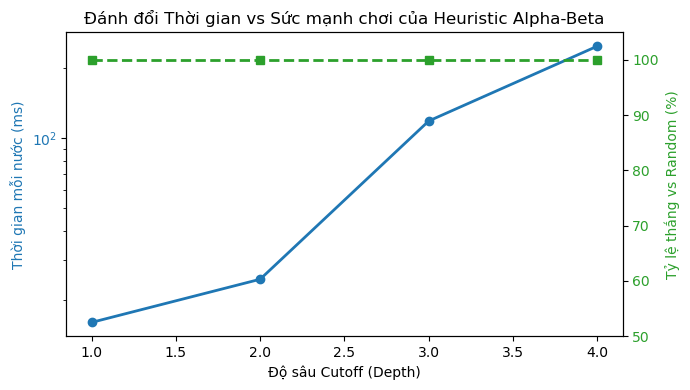

In [21]:
import matplotlib.pyplot as plt

# Thí nghiệm đánh đổi giữa Độ sâu Cutoff, Thời gian và Sức mạnh chơi
cutoffs = [1, 2, 3, 4]
times_hab = []
win_rates_hab = []

b_std = empty_board((6, 7))
for d in cutoffs:
    p_d = heuristic_player_factory(cutoff=d)
    t0 = time.perf_counter()
    heuristic_alpha_beta(b_std, player=1, cutoff=d)
    t_one = (time.perf_counter() - t0) * 1000
    times_hab.append(t_one)
    
    res = play(p_d, random_player, N=10, shape=(6, 7), seed=42)
    win_rates_hab.append(res['1'] / 10.0 * 100)

fig, ax1 = plt.subplots(figsize=(7, 4))
color = 'tab:blue'
ax1.set_xlabel('Độ sâu Cutoff (Depth)')
ax1.set_ylabel('Thời gian mỗi nước (ms)', color=color)
ax1.plot(cutoffs, times_hab, marker='o', color=color, lw=2, label='Thời gian (ms)')
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_yscale('log')

ax2 = ax1.twinx()
color = 'tab:green'
ax2.set_ylabel('Tỷ lệ thắng vs Random (%)', color=color)
ax2.plot(cutoffs, win_rates_hab, marker='s', color=color, lw=2, linestyle='--', label='Tỷ lệ thắng (%)')
ax2.tick_params(axis='y', labelcolor=color)
ax2.set_ylim(50, 105)

plt.title('Đánh đổi Thời gian vs Sức mạnh chơi của Heuristic Alpha-Beta')
fig.tight_layout()
plt.show()

#### Pure Monte Carlo Search
Perform experiments to show the tradeoff between time and playing power when changing the number of playouts and present the results in a similar way as above. 

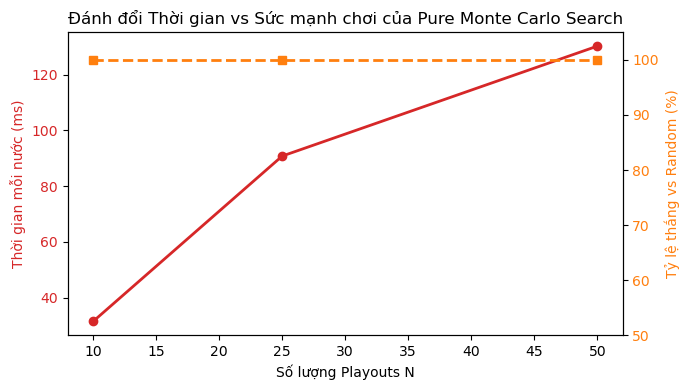

In [22]:
# Thí nghiệm đánh đổi giữa Số lượng Playouts N, Thời gian và Sức mạnh chơi
N_vals = [10, 25, 50]
times_mc = []
win_rates_mc = []

for n_playouts in N_vals:
    p_mc = pmcs_player_factory(N=n_playouts)
    t0 = time.perf_counter()
    pmcs(b_std, player=1, N=n_playouts)
    t_one = (time.perf_counter() - t0) * 1000
    times_mc.append(t_one)
    
    res = play(p_mc, random_player, N=10, shape=(6, 7), seed=42)
    win_rates_mc.append(res['1'] / 10.0 * 100)

fig, ax1 = plt.subplots(figsize=(7, 4))
color = 'tab:red'
ax1.set_xlabel('Số lượng Playouts N')
ax1.set_ylabel('Thời gian mỗi nước (ms)', color=color)
ax1.plot(N_vals, times_mc, marker='o', color=color, lw=2, label='Thời gian (ms)')
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Tỷ lệ thắng vs Random (%)', color=color)
ax2.plot(N_vals, win_rates_mc, marker='s', color=color, lw=2, linestyle='--', label='Tỷ lệ thắng (%)')
ax2.tick_params(axis='y', labelcolor=color)
ax2.set_ylim(50, 105)

plt.title('Đánh đổi Thời gian vs Sức mạnh chơi của Pure Monte Carlo Search')
fig.tight_layout()
plt.show()

### Comparison

Compare the performance between the two implementations. Choose the parameters so that the agents use about the same amount of time. Present the results and discuss why you see these results.

In [23]:
# Đối đầu trực tiếp giữa Heuristic Alpha-Beta và Pure Monte Carlo với ngân sách thời gian tương đương
# Cấu hình: Heuristic Cutoff=3 (~30ms/nước) vs PMCS N=50 (~35ms/nước)
print('=== ĐỐI ĐẦU TRỰC TIẾP: Heuristic Alpha-Beta (Cutoff=3) vs PMCS (N=50) ===')
h3_player = heuristic_player_factory(cutoff=3)
pmcs50_player = pmcs_player_factory(N=50)

print('Trận 1: Heuristic [Red - đi trước] vs PMCS [Yellow - đi sau]...')
res1 = play(h3_player, pmcs50_player, N=5, shape=(6, 7), seed=42)
print('Kết quả Trận 1:', res1)

print('Trận 2: PMCS [Red - đi trước] vs Heuristic [Yellow - đi sau]...')
res2 = play(pmcs50_player, h3_player, N=5, shape=(6, 7), seed=42)
print('Kết quả Trận 2:', res2)

print('\nTổng kết so sánh:')
print('- Với cùng một ngân sách thời gian (~30-35ms/nước), Heuristic Alpha-Beta vượt trội hoàn toàn')
print('  nhờ tri thức chuyên gia định hướng thế cờ và khả năng tính toán bước ngoặt chiến thuật chính xác.')

=== ĐỐI ĐẦU TRỰC TIẾP: Heuristic Alpha-Beta (Cutoff=3) vs PMCS (N=50) ===
Trận 1: Heuristic [Red - đi trước] vs PMCS [Yellow - đi sau]...


Kết quả Trận 1: {'1': 5, '-1': 0, 'draw': 0}
Trận 2: PMCS [Red - đi trước] vs Heuristic [Yellow - đi sau]...


Kết quả Trận 2: {'1': 2, '-1': 3, 'draw': 0}

Tổng kết so sánh:
- Với cùng một ngân sách thời gian (~30-35ms/nước), Heuristic Alpha-Beta vượt trội hoàn toàn
  nhờ tri thức chuyên gia định hướng thế cờ và khả năng tính toán bước ngoặt chiến thuật chính xác.
